In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import random

In [2]:
# Load MNIST data
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

In [3]:
print(x_train.shape)

(60000, 28, 28)


In [4]:
# Normalize

# Normalize using min–max range
m, n = np.max(x_train), np.min(x_train)
normalised_value = m-n
print(f"Max pixel value: {m}")
print(f"Min pixel value: {n}")
x_train, x_test = x_train/normalised_value, x_test/normalised_value

Max pixel value: 255
Min pixel value: 0


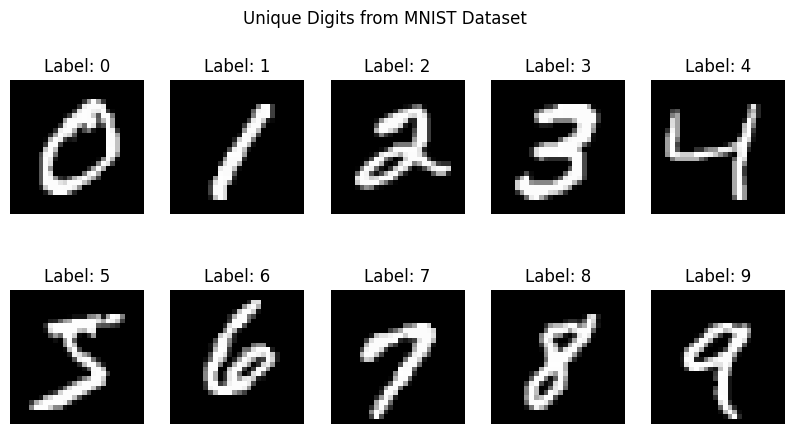

In [5]:
# Visualize unique digits
unique_labels, idx = np.unique(y_train, return_index=True)
fig, ax = plt.subplots(2, 5, figsize=(10, 5))
for i, label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]], cmap='gray')
    ax.flat[i].set_title(f"Label: {label}")
    ax.flat[i].axis('off')
plt.suptitle("Unique Digits from MNIST Dataset")
plt.show()

In [6]:
# --------------------------------------------------
# 1. Model 1 - Learning Rate = 0.001
# --------------------------------------------------

model1 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model1.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history1 = model1.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss1, acc1 = model1.evaluate(x_test, y_test, verbose=2)
print(f"Model 1 Test Accuracy: {acc1 * 100:.2f}%")


C:\Users\Vivek Negi\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1500/1500 - 3s - 2ms/step - accuracy: 0.3229 - loss: 2.0991 - val_accuracy: 0.6358 - val_loss: 1.7336
Epoch 2/10
1500/1500 - 2s - 2ms/step - accuracy: 0.5950 - loss: 1.4712 - val_accuracy: 0.7700 - val_loss: 0.9932
Epoch 3/10
1500/1500 - 2s - 2ms/step - accuracy: 0.7119 - loss: 0.9887 - val_accuracy: 0.8368 - val_loss: 0.6597
Epoch 4/10
1500/1500 - 2s - 2ms/step - accuracy: 0.7692 - loss: 0.7697 - val_accuracy: 0.8633 - val_loss: 0.5231
Epoch 5/10
1500/1500 - 2s - 2ms/step - accuracy: 0.8018 - loss: 0.6597 - val_accuracy: 0.8752 - val_loss: 0.4509
Epoch 6/10
1500/1500 - 2s - 2ms/step - accuracy: 0.8228 - loss: 0.5922 - val_accuracy: 0.8861 - val_loss: 0.4055
Epoch 7/10
1500/1500 - 2s - 2ms/step - accuracy: 0.8360 - loss: 0.5459 - val_accuracy: 0.8963 - val_loss: 0.3743
Epoch 8/10
1500/1500 - 2s - 2ms/step - accuracy: 0.8483 - loss: 0.5060 - val_accuracy: 0.9022 - val_loss: 0.3494
Epoch 9/10
1500/1500 - 3s - 2ms/step - accuracy: 0.8560 - loss: 0.4793 - val_accuracy: 0.9064 - 

In [7]:
# --------------------------------------------------
# 2. Model 2 - Learning Rate = 0.005
# --------------------------------------------------

model2 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model2.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss2, acc2 = model2.evaluate(x_test, y_test, verbose=2)
print(f"Model 2 Test Accuracy: {acc2 * 100:.2f}%")

Epoch 1/10
1500/1500 - 3s - 2ms/step - accuracy: 0.6121 - loss: 1.2642 - val_accuracy: 0.8789 - val_loss: 0.4581
Epoch 2/10
1500/1500 - 3s - 2ms/step - accuracy: 0.8471 - loss: 0.5133 - val_accuracy: 0.9109 - val_loss: 0.3177
Epoch 3/10
1500/1500 - 3s - 2ms/step - accuracy: 0.8805 - loss: 0.4005 - val_accuracy: 0.9230 - val_loss: 0.2663
Epoch 4/10
1500/1500 - 3s - 2ms/step - accuracy: 0.8997 - loss: 0.3431 - val_accuracy: 0.9322 - val_loss: 0.2351
Epoch 5/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9108 - loss: 0.3031 - val_accuracy: 0.9390 - val_loss: 0.2100
Epoch 6/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9195 - loss: 0.2744 - val_accuracy: 0.9442 - val_loss: 0.1919
Epoch 7/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9256 - loss: 0.2490 - val_accuracy: 0.9480 - val_loss: 0.1781
Epoch 8/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9317 - loss: 0.2292 - val_accuracy: 0.9508 - val_loss: 0.1661
Epoch 9/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9367 - loss: 0.2113 - val_accuracy: 0.9552 - 

In [8]:

# --------------------------------------------------
# 3. Model 3 - Learning Rate = 0.01
# --------------------------------------------------

model3 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
model3.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history3 = model3.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss3, acc3 = model3.evaluate(x_test, y_test, verbose=2)
print(f"Model 3 Test Accuracy: {acc3 * 100:.2f}%")

Epoch 1/10
1500/1500 - 4s - 2ms/step - accuracy: 0.7439 - loss: 0.8499 - val_accuracy: 0.9082 - val_loss: 0.3255
Epoch 2/10
1500/1500 - 3s - 2ms/step - accuracy: 0.8863 - loss: 0.3815 - val_accuracy: 0.9308 - val_loss: 0.2420
Epoch 3/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9131 - loss: 0.2978 - val_accuracy: 0.9412 - val_loss: 0.1998
Epoch 4/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9258 - loss: 0.2488 - val_accuracy: 0.9513 - val_loss: 0.1705
Epoch 5/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9354 - loss: 0.2163 - val_accuracy: 0.9550 - val_loss: 0.1524
Epoch 6/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9426 - loss: 0.1935 - val_accuracy: 0.9592 - val_loss: 0.1392
Epoch 7/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9480 - loss: 0.1725 - val_accuracy: 0.9630 - val_loss: 0.1274
Epoch 8/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9517 - loss: 0.1597 - val_accuracy: 0.9646 - val_loss: 0.1208
Epoch 9/10
1500/1500 - 2s - 1ms/step - accuracy: 0.9552 - loss: 0.1484 - val_accuracy: 0.9673 - 

In [9]:
# --------------------------------------------------
# 4. Model 4 - Learning Rate = 0.05
# --------------------------------------------------

model4 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
model4.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.05),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history4 = model4.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss4, acc4 = model4.evaluate(x_test, y_test, verbose=2)
print(f"Model 4 Test Accuracy: {acc4 * 100:.2f}%")


Epoch 1/10
1500/1500 - 3s - 2ms/step - accuracy: 0.8674 - loss: 0.4351 - val_accuracy: 0.9488 - val_loss: 0.1723
Epoch 2/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9426 - loss: 0.1896 - val_accuracy: 0.9618 - val_loss: 0.1284
Epoch 3/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9565 - loss: 0.1419 - val_accuracy: 0.9679 - val_loss: 0.1062
Epoch 4/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9643 - loss: 0.1155 - val_accuracy: 0.9706 - val_loss: 0.0954
Epoch 5/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9696 - loss: 0.1002 - val_accuracy: 0.9706 - val_loss: 0.0966
Epoch 6/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9730 - loss: 0.0863 - val_accuracy: 0.9740 - val_loss: 0.0869
Epoch 7/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9760 - loss: 0.0743 - val_accuracy: 0.9764 - val_loss: 0.0787
Epoch 8/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9781 - loss: 0.0685 - val_accuracy: 0.9779 - val_loss: 0.0782
Epoch 9/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9810 - loss: 0.0592 - val_accuracy: 0.9757 - 

In [11]:
# --------------------------------------------------
# 5. Model 5 - Learning Rate = 0.1
# --------------------------------------------------

model5 = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
model5.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history5 = model5.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2
)

loss5, acc5 = model5.evaluate(x_test, y_test, verbose=2)
print(f"Model 5 Test Accuracy: {acc5 * 100:.2f}%")


Epoch 1/10
1500/1500 - 3s - 2ms/step - accuracy: 0.8875 - loss: 0.3674 - val_accuracy: 0.9554 - val_loss: 0.1543
Epoch 2/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9506 - loss: 0.1637 - val_accuracy: 0.9632 - val_loss: 0.1215
Epoch 3/10
1500/1500 - 3s - 2ms/step - accuracy: 0.9620 - loss: 0.1249 - val_accuracy: 0.9710 - val_loss: 0.1005
Epoch 4/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9698 - loss: 0.1009 - val_accuracy: 0.9739 - val_loss: 0.0935
Epoch 5/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9733 - loss: 0.0848 - val_accuracy: 0.9742 - val_loss: 0.0886
Epoch 6/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9765 - loss: 0.0754 - val_accuracy: 0.9768 - val_loss: 0.0816
Epoch 7/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9782 - loss: 0.0680 - val_accuracy: 0.9768 - val_loss: 0.0842
Epoch 8/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9808 - loss: 0.0595 - val_accuracy: 0.9774 - val_loss: 0.0795
Epoch 9/10
1500/1500 - 2s - 2ms/step - accuracy: 0.9822 - loss: 0.0538 - val_accuracy: 0.9786 - 

In [12]:

print("\nFinal Test Accuracy Comparison:")

print(f"Learning Rate 0.001 : {acc1 * 100:.2f}%")
print(f"Learning Rate 0.005 : {acc2 * 100:.2f}%")
print(f"Learning Rate 0.01  : {acc3 * 100:.2f}%")
print(f"Learning Rate 0.05  : {acc4 * 100:.2f}%")
print(f"Learning Rate 0.1   : {acc5 * 100:.2f}%")


Final Test Accuracy Comparison:
Learning Rate 0.001 : 90.58%
Learning Rate 0.005 : 95.66%
Learning Rate 0.01  : 96.73%
Learning Rate 0.05  : 97.76%
Learning Rate 0.1   : 98.19%


Enter image index (0-9999):  7


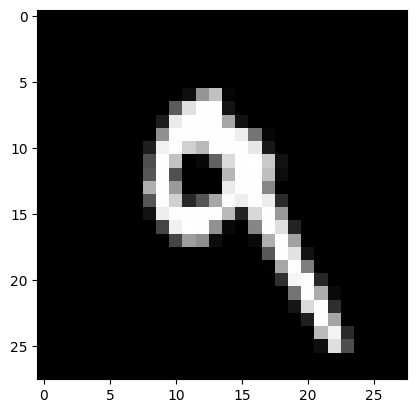

Predicted Digit: 9
Actual Digit: 9


In [13]:
# Predict 
image_index = int(input("Enter image index (0-9999): "))

plt.imshow(x_test[image_index], cmap='gray')
plt.show()

prediction = model3.predict(x_test[image_index].reshape(1, 28, 28), verbose=0)

print("Predicted Digit:", np.argmax(prediction))
print("Actual Digit:", y_test[image_index])

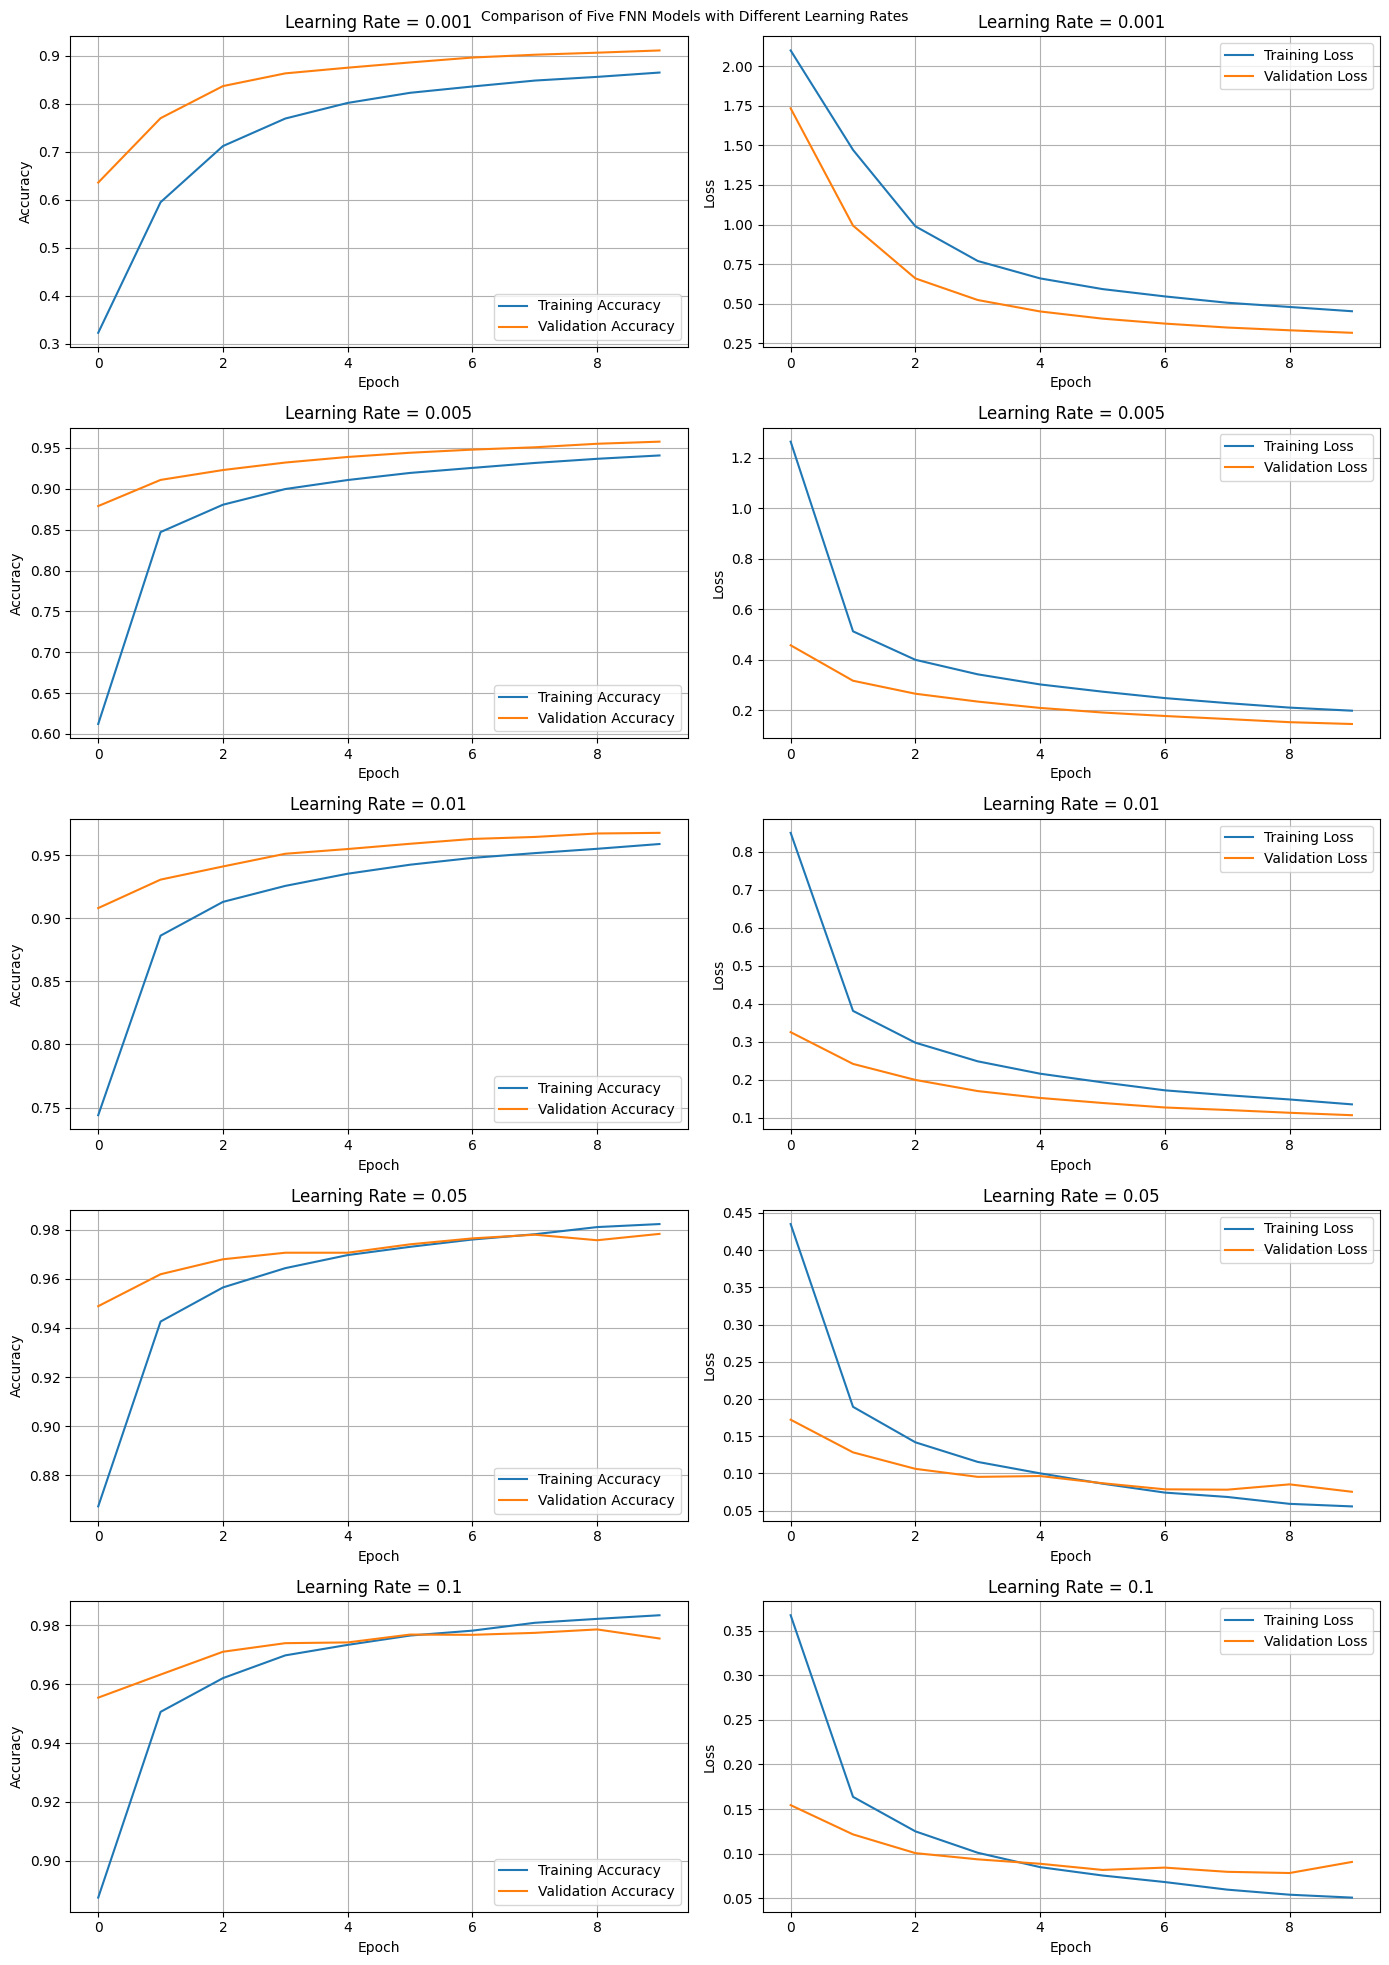

In [14]:
# Store the histories of all five models
histories = [history1, history2, history3, history4, history5]

learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]

# Create 5 rows and 2 columns of subplots
fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, history in enumerate(histories):

    # Training and validation accuracy
    axes[i, 0].plot(history.history['accuracy'], label='Training Accuracy')
    axes[i, 0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[i, 0].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 0].set_xlabel('Epoch')
    axes[i, 0].set_ylabel('Accuracy')
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    # Training and validation loss
    axes[i, 1].plot(history.history['loss'], label='Training Loss')
    axes[i, 1].plot(history.history['val_loss'], label='Validation Loss')
    axes[i, 1].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 1].set_xlabel('Epoch')
    axes[i, 1].set_ylabel('Loss')
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.suptitle('Comparison of Five FNN Models with Different Learning Rates',
             fontsize=10)

plt.tight_layout()
plt.show()